# Notebook 02 — Preprocessing Verification


## 0 · Imports

In [27]:
import sys
from pathlib import Path
PROJECT_ROOT = Path('..').resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils.config import DATA_PROC, INFORMATIVE_SENSORS, WINDOW_SIZE, RUL_CLIP

sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 120, 'figure.facecolor': 'white'})

SUBSET = 'FD001'
print('Ready.')

Ready.


## 1 · Array shapes and ranges

In [28]:
proc = DATA_PROC / SUBSET
splits = ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test']

print(f'Checking: {proc}\n')
all_ok = True
arrays = {}
for name in splits:
    p = proc / f'{name}.npy'
    if p.exists():
        arr = np.load(p)
        arrays[name] = arr
        print(f'  {name:12s}  shape={str(arr.shape):20s}  '
              f'min={arr.min():7.3f}  max={arr.max():7.3f}')
    else:
        print(f'  MISSING: {p}')
        all_ok = False

if all_ok:
    print('\nAll files present')
else:
    print('\nRun: python -m src.data.preprocessing --subset FD001')

Checking: C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\data\processed\FD001

  X_train       shape=(15332, 30, 14)       min=  0.000  max=  1.000
  y_train       shape=(15332,)              min=  0.000  max=125.000
  X_val         shape=(2399, 30, 14)        min=  0.000  max=  1.000
  y_val         shape=(2399,)               min=  0.000  max=125.000
  X_test        shape=(100, 30, 14)         min=  0.013  max=  0.977
  y_test        shape=(100,)                min=  7.000  max=125.000

All files present


## 2 · Check 1 — normalisation (sensor values in [0, 1])

In [29]:
X_train = arrays['X_train']

sensor_min = X_train.reshape(-1, X_train.shape[-1]).min(axis=0)
sensor_max = X_train.reshape(-1, X_train.shape[-1]).max(axis=0)

print('Per-sensor min and max in training windows:')
print(f"{'Sensor':<8} {'Min':>8} {'Max':>8} {'OK':>6}")
print('-' * 35)
all_norm_ok = True
for s, mn, mx in zip(INFORMATIVE_SENSORS, sensor_min, sensor_max):
    ok = (mn >= -0.01) and (mx <= 1.01)
    if not ok:
        all_norm_ok = False
    print(f'  {s:<6}  {mn:8.4f}  {mx:8.4f}  {"OK" if ok else "FAIL"}')

print(f'\nNormalisation check: {"PASSED" if all_norm_ok else "FAILED"}  ' if all_norm_ok else '\nNormalisation check: FAILED')

Per-sensor min and max in training windows:
Sensor        Min      Max     OK
-----------------------------------
  s_2       0.0000    1.0000  OK
  s_3       0.0000    1.0000  OK
  s_4       0.0000    1.0000  OK
  s_7       0.0000    1.0000  OK
  s_8       0.0000    0.9395  OK
  s_9       0.0000    0.9783  OK
  s_11      0.0000    1.0000  OK
  s_12      0.0000    1.0000  OK
  s_13      0.0000    1.0000  OK
  s_14      0.0149    0.9821  OK
  s_15      0.0000    1.0000  OK
  s_17      0.0000    1.0000  OK
  s_20      0.0000    1.0000  OK
  s_21      0.0000    0.9921  OK

Normalisation check: PASSED  


## 3 · Check 2 — RUL clipping (labels in [0, 125])

In [30]:
for split in ['y_train', 'y_val', 'y_test']:
    y = arrays[split]
    above = (y > RUL_CLIP).sum()
    below = (y < 0).sum()
    print(f'  {split:12s}  min={y.min():.1f}  max={y.max():.1f}  '
          f'above_cap={above}  below_zero={below}')

print(f'\nRUL cap ({RUL_CLIP}) check: {"PASSED" if above == 0 and below == 0 else "FAILED"}')

  y_train       min=0.0  max=125.0  above_cap=0  below_zero=0
  y_val         min=0.0  max=125.0  above_cap=0  below_zero=0
  y_test        min=7.0  max=125.0  above_cap=0  below_zero=0

RUL cap (125) check: PASSED


## 4 · Check 3 — no leakage between train and val

In [31]:
# If there is leakage, some windows will be identical in both splits.
# We check by hashing each window and looking for collisions.
def window_hashes(X):
    return set(hash(w.tobytes()) for w in X)

tr_hashes = window_hashes(arrays['X_train'])
va_hashes = window_hashes(arrays['X_val'])
overlap   = tr_hashes & va_hashes

print(f'Train windows : {len(tr_hashes):,}')
print(f'Val windows   : {len(va_hashes):,}')
print(f'Overlapping   : {len(overlap)}')
print(f'\nLeakage check : {"PASSED — no overlap" if len(overlap) == 0 else "FAILED — overlap found"}')

Train windows : 15,332
Val windows   : 2,399
Overlapping   : 0

Leakage check : PASSED — no overlap


## 5 · RUL distributions — train, val, test

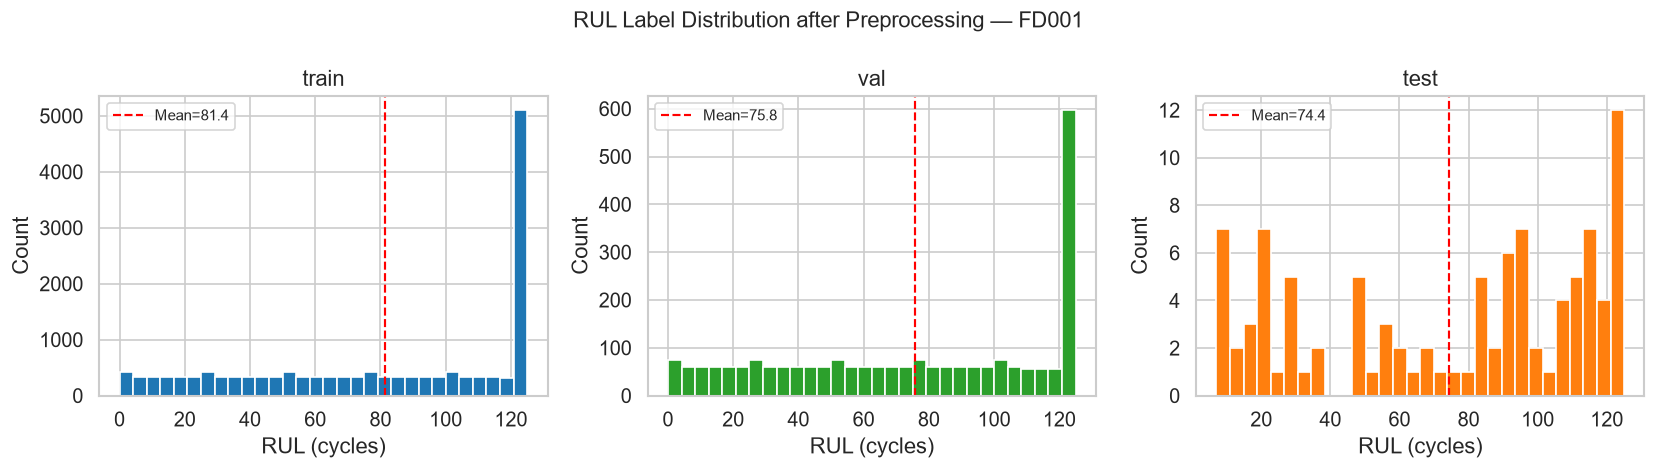

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
colors = ['#1f77b4', '#2ca02c', '#ff7f0e']

for ax, split, col in zip(axes, ['y_train', 'y_val', 'y_test'], colors):
    y = arrays[split]
    ax.hist(y, bins=30, color=col, edgecolor='white')
    ax.axvline(y.mean(), color='red', linestyle='--', lw=1.3,
               label=f'Mean={y.mean():.1f}')
    ax.set_title(split.replace('y_', ''))
    ax.set_xlabel('RUL (cycles)')
    ax.set_ylabel('Count')
    ax.legend(fontsize=9)

fig.suptitle(f'RUL Label Distribution after Preprocessing — {SUBSET}', fontsize=13)
plt.tight_layout()
plt.show()

## 6 · Window contents — visualise sample windows at different RUL levels

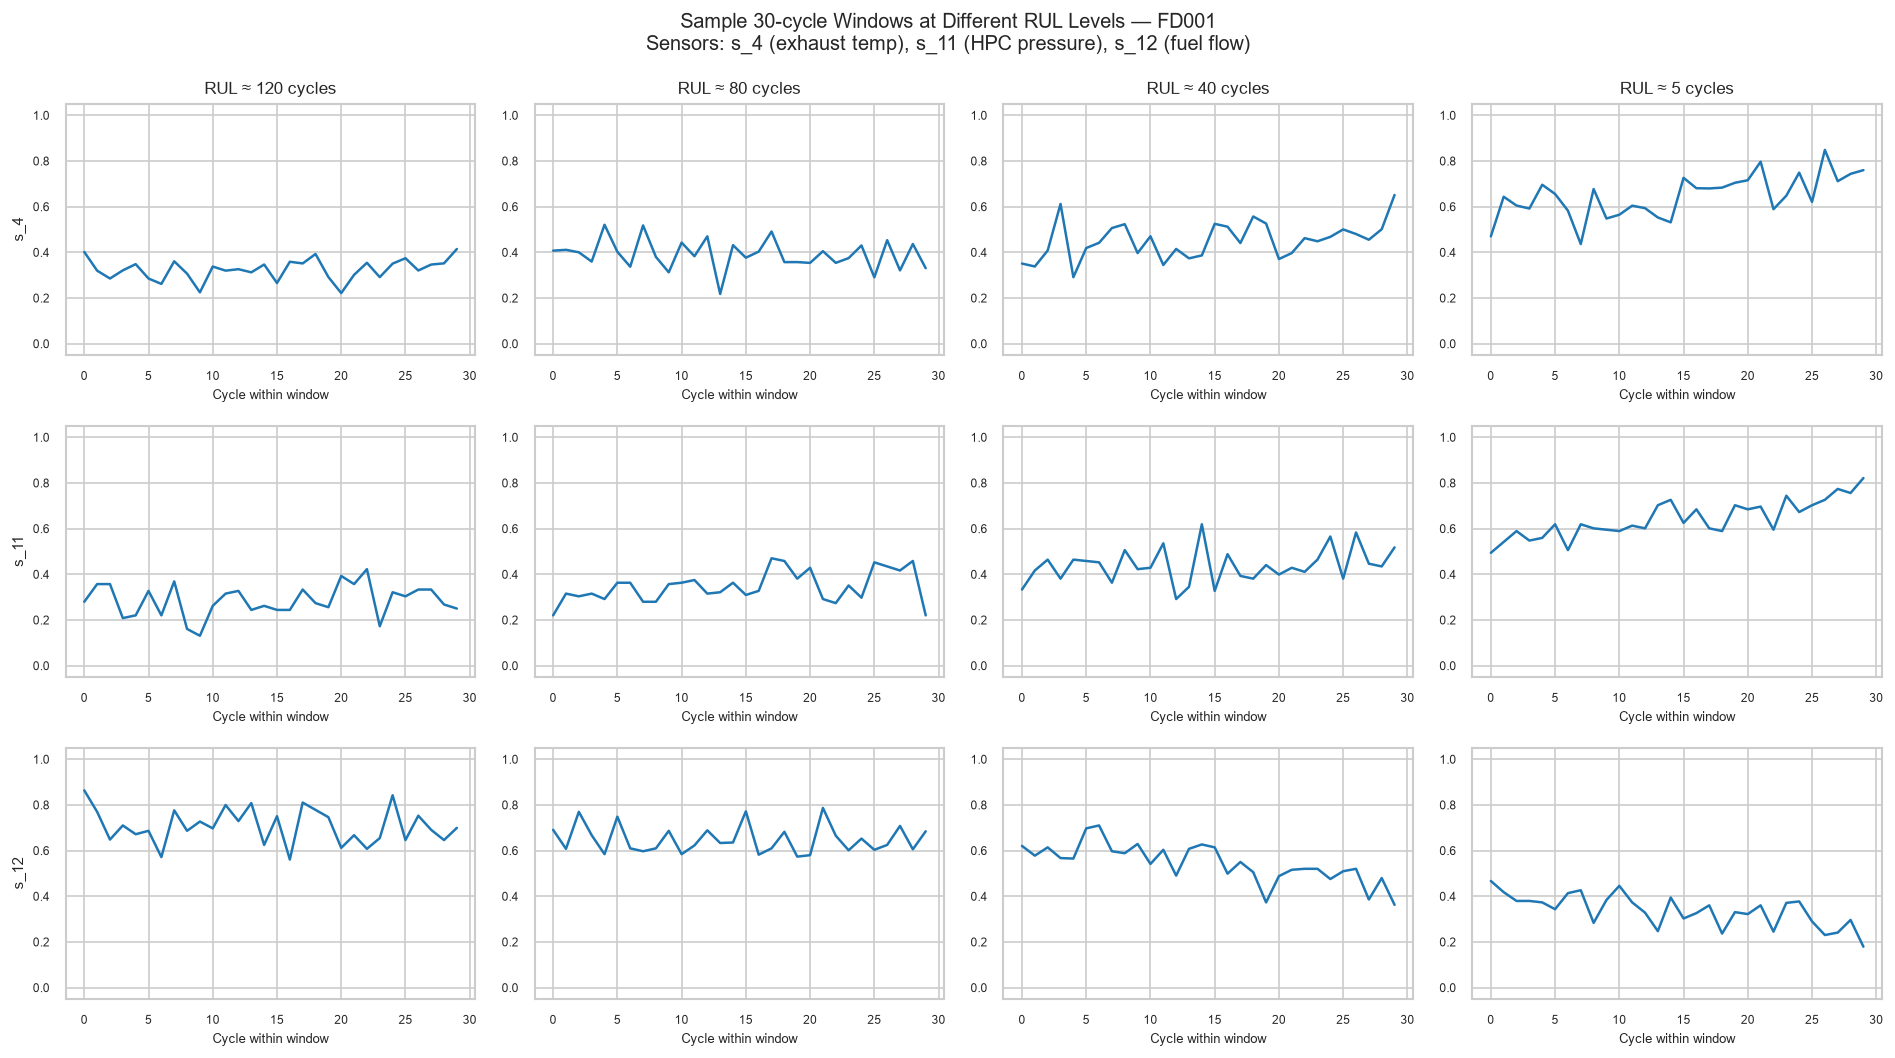

This confirms the preprocessing preserved the degradation signal.


In [33]:
X_tr = arrays['X_train']
y_tr = arrays['y_train']

# Pick 4 windows: high RUL (healthy), mid RUL, low RUL (near failure)
targets = [120, 80, 40, 5]
PLOT_SENSORS = ['s_4', 's_11', 's_12']   # top 3 RUL-correlated sensors
sensor_idx   = [INFORMATIVE_SENSORS.index(s) for s in PLOT_SENSORS]

fig, axes = plt.subplots(len(PLOT_SENSORS), len(targets), figsize=(16, 9))

for col, target_rul in enumerate(targets):
    # Find closest window to this RUL
    idx = np.argmin(np.abs(y_tr - target_rul))
    window = X_tr[idx]   # shape (30, 14)
    actual_rul = y_tr[idx]

    for row, (sensor_name, si) in enumerate(zip(PLOT_SENSORS, sensor_idx)):
        ax = axes[row][col]
        ax.plot(window[:, si], color='#1f77b4', lw=1.5)
        ax.set_ylim(-0.05, 1.05)
        if row == 0:
            ax.set_title(f'RUL ≈ {actual_rul:.0f} cycles', fontsize=10)
        if col == 0:
            ax.set_ylabel(sensor_name, fontsize=9)
        ax.tick_params(labelsize=7)
        ax.set_xlabel('Cycle within window', fontsize=8)

fig.suptitle(
    f'Sample 30-cycle Windows at Different RUL Levels — {SUBSET}\n'
    f'Sensors: s_4 (exhaust temp), s_11 (HPC pressure), s_12 (fuel flow)',
    fontsize=12
)
plt.tight_layout()
plt.show()

print('This confirms the preprocessing preserved the degradation signal.')

## 7 · Cross-subset summary (run all 4 subsets first)

In [34]:
print(f"{'Subset':<8} {'Train':>10} {'Val':>8} {'Test':>8} {'y_train mean':>14} {'y_test mean':>12}")
print('-' * 60)
for s in ['FD001', 'FD002', 'FD003', 'FD004']:
    p = DATA_PROC / s
    if not (p / 'X_train.npy').exists():
        print(f'  {s:<6}  not yet preprocessed')
        continue
    X_tr = np.load(p / 'X_train.npy')
    X_va = np.load(p / 'X_val.npy')
    X_te = np.load(p / 'X_test.npy')
    y_tr = np.load(p / 'y_train.npy')
    y_te = np.load(p / 'y_test.npy')
    print(f'  {s:<6}  {X_tr.shape[0]:>10,}  {X_va.shape[0]:>8,}  '
          f'{X_te.shape[0]:>8,}  {y_tr.mean():>14.1f}  {y_te.mean():>12.1f}')

Subset        Train      Val     Test   y_train mean  y_test mean
------------------------------------------------------------
  FD001       15,332     2,399       100            81.4          74.4
  FD002       39,424     6,795       253            80.9          72.5
  FD003       18,749     3,071       100            89.3          73.8
  FD004       45,594     8,434       237            88.4          75.7


## 8 · Summary

In [37]:
print("""
--------------------------------------------------
         PREPROCESSING VERIFICATION SUMMARY                  
--------------------------------------------------
  -> Array shapes correct  (N, 30, 14) and (N,)             
  -> Sensor values in [0, 1]  —  normalisation OK           
  -> RUL labels in [0, 125]  —  clipping OK                 
  -> No window overlap between train and val                 
  -> Degradation signal visible in sample windows                           

""")


--------------------------------------------------
         PREPROCESSING VERIFICATION SUMMARY                  
--------------------------------------------------
  -> Array shapes correct  (N, 30, 14) and (N,)             
  -> Sensor values in [0, 1]  —  normalisation OK           
  -> RUL labels in [0, 125]  —  clipping OK                 
  -> No window overlap between train and val                 
  -> Degradation signal visible in sample windows                           


